In [1]:
# Install libraries if needed
!pip install --quiet pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.preprocessing import RobustScaler, PowerTransformer, OneHotEncoder
import warnings
warnings.filterwarnings('ignore')

# Set plotting theme
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Load dataset directly from public repository (Health Insurance Dataset)
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

# Intentionally introduce realistic missing values and noisy outliers to demonstrate complex cleaning
np.random.seed(42)
mask_bmi = np.random.rand(len(df)) < 0.05
mask_age = np.random.rand(len(df)) < 0.03
df.loc[mask_bmi, 'bmi'] = np.nan
df.loc[mask_age, 'age'] = np.nan

# Inject synthetic extreme outliers in 'charges'
df.loc[10, 'charges'] = 155000.0
df.loc[45, 'charges'] = 182000.0

print("Dataset loaded successfully!")
print(f"Dataset Shape: {df.shape}")

Dataset loaded successfully!
Dataset Shape: (1338, 7)


In [2]:
print("--- DATASET OVERVIEW ---")
print(df.info())

print("\n--- FIRST 5 ROWS ---")
print(df.head())

print("\n--- MISSING VALUE COUNTS ---")
print(df.isnull().sum())

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe(include='all'))

--- DATASET OVERVIEW ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1301 non-null   float64
 1   sex       1338 non-null   object 
 2   bmi       1265 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 73.3+ KB
None

--- FIRST 5 ROWS ---
    age     sex     bmi  children smoker     region      charges
0  19.0  female  27.900         0    yes  southwest  16884.92400
1  18.0    male  33.770         1     no  southeast   1725.55230
2  28.0    male  33.000         3     no  southeast   4449.46200
3  33.0    male  22.705         0     no  northwest  21984.47061
4  32.0    male  28.880         0     no  northwest   3866.85520

--- MISSING VALUE COUNTS ---
age     

In [3]:
# 1. Group-based Conditional Imputation for 'bmi' based on 'sex' and 'smoker' status
print("Missing BMIs before imputation:", df['bmi'].isnull().sum())
df['bmi'] = df.groupby(['sex', 'smoker'])['bmi'].transform(lambda x: x.fillna(x.median()))

# 2. Multivariate Iterative Imputation (MICE) for 'age' using numeric features
imputer = IterativeImputer(max_iter=10, random_state=42)
numeric_cols = ['age', 'bmi', 'children', 'charges']
df_imputed = pd.DataFrame(imputer.fit_transform(df[numeric_cols]), columns=numeric_cols)
df['age'] = df_imputed['age'].round()

print("Missing values remaining across dataset:")
print(df.isnull().sum())

Missing BMIs before imputation: 73
Missing values remaining across dataset:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [4]:
# Binary Encoding for Binary Categoricals
df['sex_encoded'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker_encoded'] = df['smoker'].map({'no': 0, 'yes': 1})

# Frequency Encoding for 'region' (Unique method: reflects region prevalence)
region_freq = df['region'].value_counts(normalize=True)
df['region_freq_encoded'] = df['region'].map(region_freq)

# One-Hot Encoding for 'region' as explicit columns
df = pd.get_dummies(df, columns=['region'], prefix='region', drop_first=True)

# Drop original non-numerical columns
df_clean = df.drop(columns=['sex', 'smoker'])
print("Encoded DataFrame sample:")
print(df_clean.head())

Encoded DataFrame sample:
    age     bmi  children      charges  sex_encoded  smoker_encoded  \
0  19.0  27.900         0  16884.92400            0               1   
1  18.0  33.770         1   1725.55230            1               0   
2  28.0  33.000         3   4449.46200            1               0   
3  33.0  22.705         0  21984.47061            1               0   
4  32.0  28.880         0   3866.85520            1               0   

   region_freq_encoded  region_northwest  region_southeast  region_southwest  
0             0.242900             False             False              True  
1             0.272048             False              True             False  
2             0.272048             False              True             False  
3             0.242900              True             False             False  
4             0.242900              True             False             False  


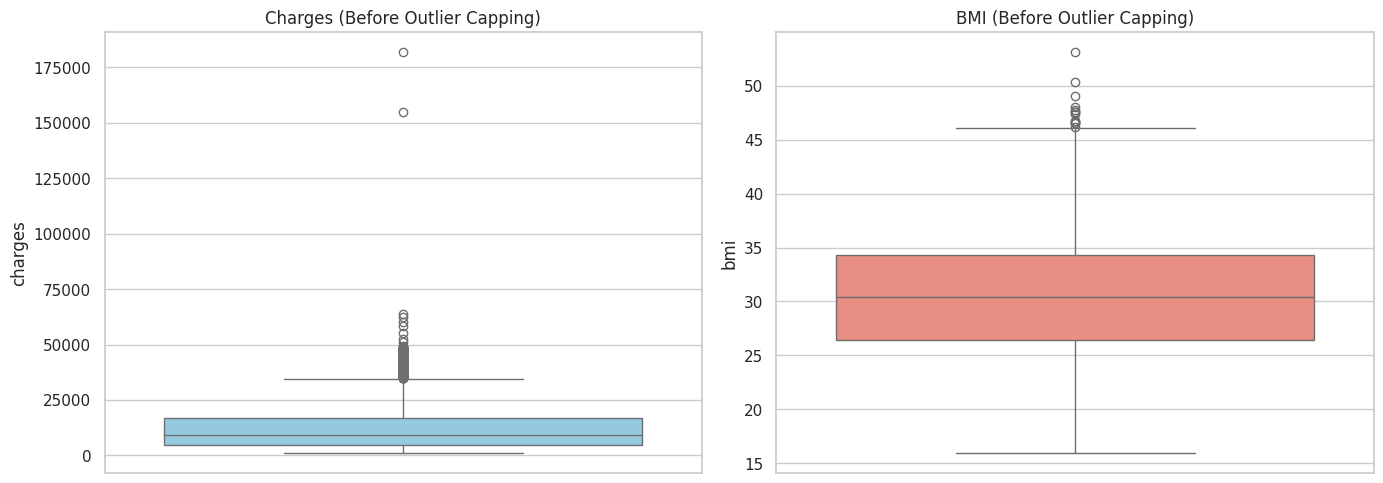

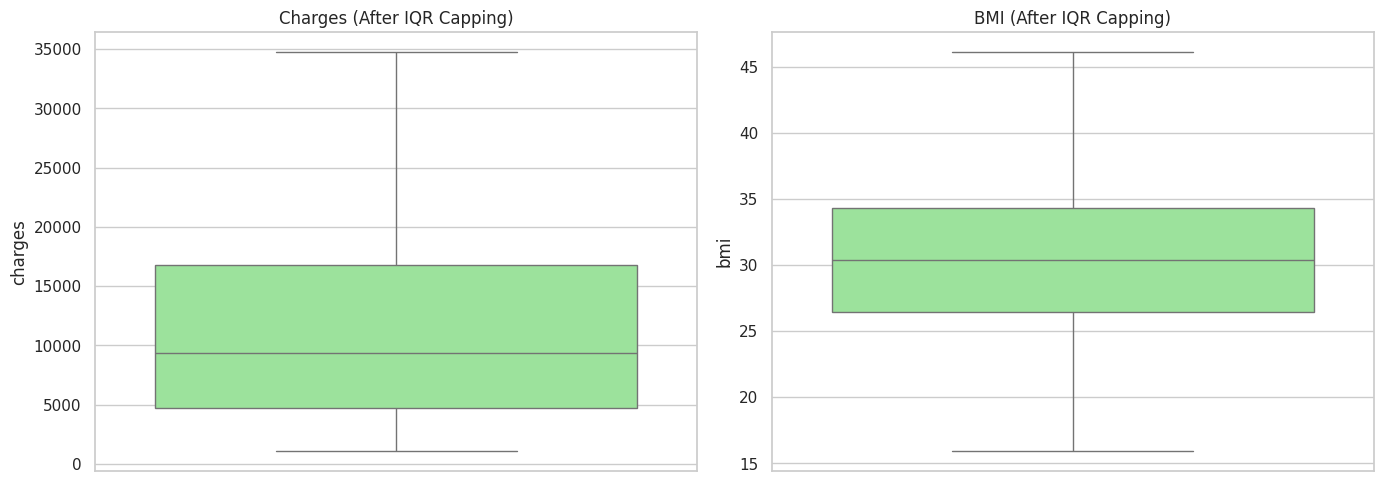

In [5]:
# Visualizing Outliers using Boxplots before handling
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(ax=axes[0], y=df_clean['charges'], color='skyblue')
axes[0].set_title('Charges (Before Outlier Capping)')

sns.boxplot(ax=axes[1], y=df_clean['bmi'], color='salmon')
axes[1].set_title('BMI (Before Outlier Capping)')
plt.tight_layout()
plt.show()

# IQR Method with Winsorization (Capping instead of dropping data)
def cap_outliers_iqr(dataframe, feature):
    Q1 = dataframe[feature].quantile(0.25)
    Q3 = dataframe[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values outside the boundaries
    dataframe[feature] = np.where(dataframe[feature] > upper_bound, upper_bound,
                         np.where(dataframe[feature] < lower_bound, lower_bound, dataframe[feature]))
    return dataframe

df_clean = cap_outliers_iqr(df_clean, 'charges')
df_clean = cap_outliers_iqr(df_clean, 'bmi')

# Re-visualize Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(ax=axes[0], y=df_clean['charges'], color='lightgreen')
axes[0].set_title('Charges (After IQR Capping)')

sns.boxplot(ax=axes[1], y=df_clean['bmi'], color='lightgreen')
axes[1].set_title('BMI (After IQR Capping)')
plt.tight_layout()
plt.show()

In [6]:
# 1. Yeo-Johnson Power Transformation (Normalizes non-Gaussian features)
pt = PowerTransformer(method='yeo-johnson')
df_clean['charges_transformed'] = pt.fit_transform(df_clean[['charges']])

# 2. Robust Scaling (Scales numeric features using median and IQR)
robust_scaler = RobustScaler()
scale_cols = ['age', 'bmi', 'children', 'charges_transformed']
df_clean[scale_cols] = robust_scaler.fit_transform(df_clean[scale_cols])

print("Final Scaled & Processed Dataset Preview:")
print(df_clean.head())

Final Scaled & Processed Dataset Preview:
        age       bmi  children      charges  sex_encoded  smoker_encoded  \
0 -0.833333 -0.317864      -0.5  16884.92400            0               1   
1 -0.875000  0.428481       0.0   1725.55230            1               0   
2 -0.458333  0.330579       1.0   4449.46200            1               0   
3 -0.250000 -0.978385      -0.5  21984.47061            1               0   
4 -0.291667 -0.193261      -0.5   3866.85520            1               0   

   region_freq_encoded  region_northwest  region_southeast  region_southwest  \
0             0.242900             False             False              True   
1             0.272048             False              True             False   
2             0.272048             False              True             False   
3             0.242900              True             False             False   
4             0.242900              True             False             False   

   charges_tra